In [2]:
# ============ 0. LIBRERÍAS ============
import numpy as np                      # vectores y álgebra lineal
import pandas as pd                     # leer el csv y armar la tabla
import matplotlib.pyplot as plt         # gráficas
import scipy.signal as signal           # deconvolve y convolve

In [3]:
# ============ 1. LECTURA DE DATOS ============
df = pd.read_csv("dataset2.csv")        # carga el archivo
df.head()                               # primeras filas

,t,u,y
0,0.0,0.000000,0.000000
1,0.1,-0.164896,-0.012733
2,0.2,-0.279775,-0.044337
3,0.3,-0.342929,-0.082171
4,0.4,-0.355964,-0.114187


In [4]:
# ============ 2. VARIABLES Y LONGITUD N ============
time = df.t.to_numpy()                  # tiempo
u = df.u.to_numpy()                     # entrada
y = df.y.to_numpy()                     # salida real

# signal.deconvolve divide por u[0]; en este dataset u[0] = 0, así que se descarta la 1.ª muestra.
# Como el sistema es causal y u[0] = 0, y[1:] = u[1:] * h sigue siendo exacto.
if u[0] == 0:
    time, u, y = time[1:], u[1:], y[1:]

N = len(u)                              # N se define DESPUÉS del recorte, antes de calcular p
print("N =", N, "| len(time), len(u), len(y) =", len(time), len(u), len(y))

N = 69 | len(time), len(u), len(y) = 69 69 69


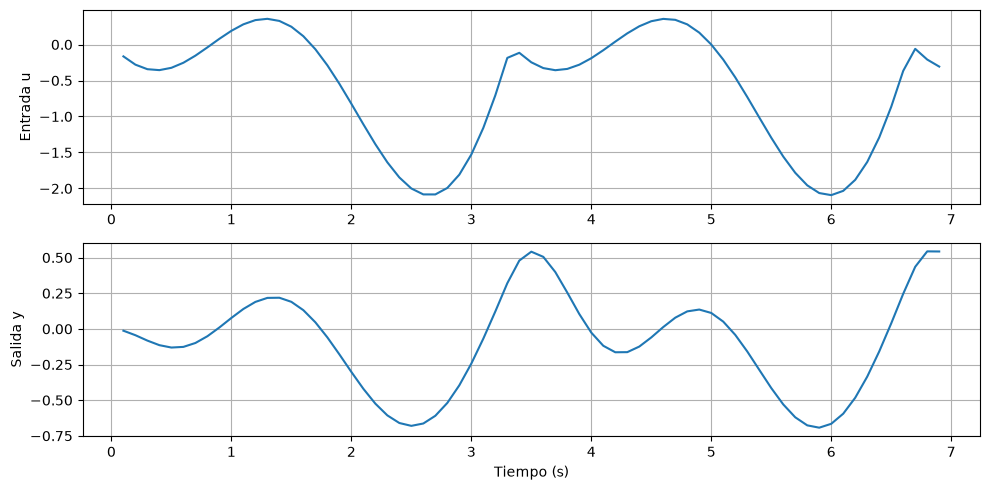

In [5]:
# Entrada y salida contra el tiempo (se usa `time`, ya recortado)
plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1)
plt.plot(time, u)
plt.ylabel("Entrada u")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, y)
plt.xlabel("Tiempo (s)")
plt.ylabel("Salida y")
plt.grid(True)

plt.tight_layout()
plt.show()

In [6]:
# ============ 3. VALOR DE p (versión asignada) ============
# Versión 1: p1 = 0.5*N y p2 = N.
# Versión 2: 0.3*N y 0.8*N.  Versión 3: 0.6*N y 0.9*N.  (cambia solo estos dos factores)
p1 = round(0.5 * N)                     # p de la PRUEBA 1
p2 = round(1.0 * N)                     # p de la PRUEBA 2
print(f"N = {N} | p1 = {p1} | p2 = {p2}")

N = 69 | p1 = 34 | p2 = 69


In [7]:
# ============ 4. FUNCIONES DE IDENTIFICACIÓN ============
def LSE(t, u, y, p):
    """Mínimo error cuadrático: h que minimiza ||y - U h||^2."""
    N = len(u)                          # longitud real de las señales
    T = np.mean(np.diff(t))             # paso de muestreo promedio
    UU = np.zeros((N, p))               # matriz de regresión N x p
    for i in range(p):                  # una columna por coeficiente de h
        if i == 0:
            UU[:, 0] = u                # columna 0: la entrada completa
        else:
            UU[i:, i] = u[:N - i]       # columna i: entrada retrasada i muestras
    UU *= T                             # escala por el tiempo de muestreo
    theta, *_ = np.linalg.lstsq(UU, y, rcond=None)   # lstsq no falla con p cercano a N
    return theta * T                    # h = solución * T

def deconvolucion(u, y, p):
    """Desconvolución con zero padding de p ceros; h tiene p + 1 puntos."""
    ypad = np.concatenate([y, np.zeros(p)])   # agrega p ceros al final de la salida
    h, _ = signal.deconvolve(ypad, u)         # primero la salida, después la entrada
    return h                                  # el residuo no se usa

def predecir(h, u):
    return signal.convolve(h, u)[:len(u)]     # convolución recortada a N muestras

## 1. Identificación de los cuatro sistemas
Se requiere evaluar el desempeño de dos métodos de identificación de sistemas: desconvolución y mínimo error cuadrático, con el fin de determinar el mejor valor del parámetro p y el mejor método. Para cada prueba (PRUEBA 1 y PRUEBA 2, según la versión asignada en la tabla), identifique el sistema a partir de la entrada u y la salida y utilizando ambos métodos. En total, deberá obtener cuatro sistemas identificados.

In [8]:
h_desc_p1 = deconvolucion(u, y, p1)     # desconvolución, prueba 1
h_lse_p1  = LSE(time, u, y, p1)         # mínimos cuadrados, prueba 1
h_desc_p2 = deconvolucion(u, y, p2)     # desconvolución, prueba 2
h_lse_p2  = LSE(time, u, y, p2)         # mínimos cuadrados, prueba 2

# Salidas predichas: y_pred = u * h
y_desc_p1 = predecir(h_desc_p1, u)
y_lse_p1  = predecir(h_lse_p1, u)
y_desc_p2 = predecir(h_desc_p2, u)
y_lse_p2  = predecir(h_lse_p2, u)

## 2.  Gráficas comparativas
Realice una gráfica comparativa donde superponga la salida real con las dos salidas predichas usando los sistemas de la PRUEBA 1 (y_desc_p1 y y_lse_p1). Repita el procedimiento comparando la salida real con las dos salidas predichas usando los sistemas de la PRUEBA 2 (y_desc_p2 y y_lse_p2). Ambas figuras deben estar graficadas respecto al tiempo y deben tener leyendas.

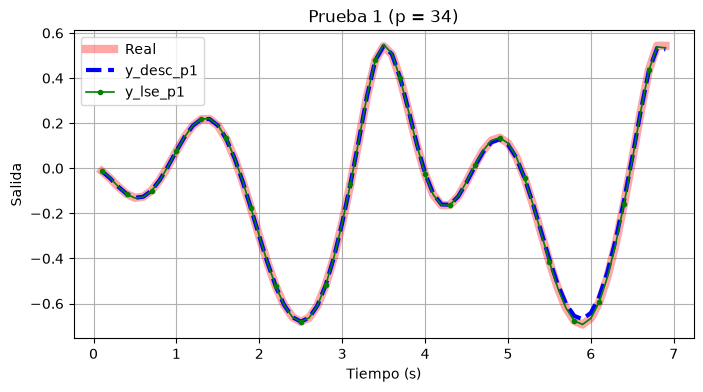

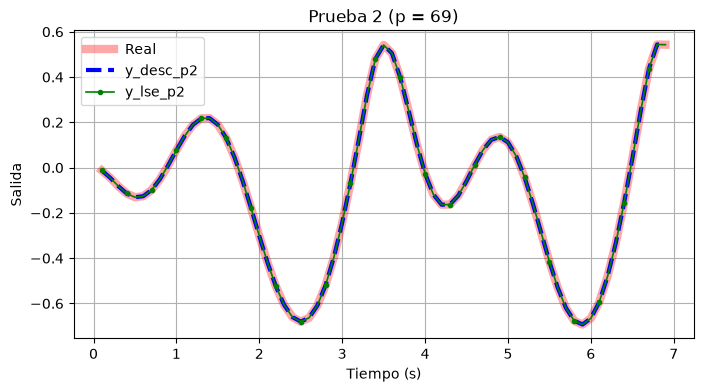

In [9]:
def graficar(time, y, y_desc, y_lse, nombre_desc, nombre_lse, titulo):
    plt.figure(figsize=(8, 4))
    # Las predicciones coinciden casi exactamente con la real, así que se dibujan con grosores distintos:
    plt.plot(time, y, color="red", linewidth=6, alpha=0.35, label="Real")            # real: gruesa, al fondo
    plt.plot(time, y_desc, color="blue", linewidth=3, linestyle="--", label=nombre_desc)  # desconvolución
    plt.plot(time, y_lse, color="green", linewidth=1.2, marker="o", markersize=3,
             markevery=3, label=nombre_lse)                                          # LSE: fina, encima
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Salida")
    plt.title(titulo)
    plt.legend()
    plt.grid(True)

graficar(time, y, y_desc_p1, y_lse_p1, "y_desc_p1", "y_lse_p1", f"Prueba 1 (p = {p1})")
graficar(time, y, y_desc_p2, y_lse_p2, "y_desc_p2", "y_lse_p2", f"Prueba 2 (p = {p2})")
plt.show()

## 3.  Errores
Use la ecuación para calcular el error entre la salida real y la salida predicha para cada caso. Anote los resultados en la Tabla.

**Error = promedio[(salida real − salida predicha)²]**

In [9]:
def error(real, pred):
    return np.mean((real - pred) ** 2)  # promedio de (real - predicha)^2

tabla = pd.DataFrame(
    {
        ("PRUEBA 1", "y_desc_p1"): [error(y, y_desc_p1)],
        ("PRUEBA 1", "y_lse_p1"):  [error(y, y_lse_p1)],
        ("PRUEBA 2", "y_desc_p2"): [error(y, y_desc_p2)],
        ("PRUEBA 2", "y_lse_p2"):  [error(y, y_lse_p2)],
    },
    index=["Error salida real vs."],
)
print(f"N = {N} | p1 = {p1} | p2 = {p2}")
print(tabla.to_string(float_format=lambda x: f"{x:.4e}"))

N = 69 | p1 = 34 | p2 = 69
                        PRUEBA 1              PRUEBA 2           
                       y_desc_p1   y_lse_p1  y_desc_p2   y_lse_p2
Error salida real vs. 6.9369e-05 3.2473e-06 4.4450e-33 8.2121e-31


## 4.  Mejor método y mejor valor de p
De acuerdo con lo observado en el numeral 2 y los cálculos del numeral 3, justifique cuál fue el mejor método para la estimación y el mejor valor de p.

**Método.** Con p1 = 34 (un p claramente menor que N), mínimos cuadrados da un error de 3.25e-06 frente a 6.94e-05 de la desconvolución, unas 20 veces menor. Es lo esperable: LSE minimiza justamente este error cuadrático, mientras que la desconvolución divide por la entrada y arrastra el ruido y el error de truncar h. Con p2 = N = 69 los dos métodos quedan en el orden de 1e-31 (4.4e-33 y 8.2e-31), que es cero numérico, así que ahí no hay un ganador real.

**Valor de p.** El error baja al subir p, pero con p = N hay tantos parámetros como datos y el modelo se limita a reproducir la muestra, ruido incluido. Un error de 1e-31 no demuestra que el sistema esté bien identificado, solo que se ajustó a estos datos. Por eso la elección razonable es **mínimos cuadrados con un p intermedio**, el menor que ya deja el error despreciable, y no el p máximo. Esa decisión se confirma con datos nuevos (numeral 5).

## 5.  Validación con un conjunto de datos adicional
Responda ampliamente: ¿cómo emplearía un conjunto de datos adicional, que incluya señales de entrada y salida, para validar que el método y el valor de p seleccionados en el numeral 4 proporcionan una identificación adecuada del sistema?

1. **Conseguir datos nuevos** (u_val, y_val) del mismo sistema, que no se usaron para identificar. La entrada debe excitar bien el sistema, con variaciones de amplitud y frecuencia parecidas o más ricas que las del conjunto original.
2. **Predecir sin reajustar.** Usar la h ya estimada (LSE con el p candidato) y calcular ŷ_val = u_val ∗ h, recortada a la longitud de y_val.
3. **Calcular el error de validación** (el mismo error cuadrático medio) y compararlo con el de identificación. También se puede reportar el R² o un error normalizado.
4. **Decidir con el criterio de generalización.** Si el error de validación es similar al de identificación, el modelo generaliza y la identificación es adecuada. Si es mucho mayor, hay sobreajuste: p es demasiado grande y el modelo aprendió ruido.
5. **Elegir p con la validación.** Repetir con p1, p2 y valores intermedios, y quedarse con el p de menor error de validación (o el menor p cuyo error ya no mejora), no con el de menor error de identificación. Hacer lo mismo con la desconvolución confirma que LSE sigue siendo mejor fuera de la muestra.
6. **Revisar los residuos** e = y_val − ŷ_val: deben parecer ruido sin estructura y sin correlación con u_val. Una forma sistemática en el residuo indica dinámica que el modelo no captó.
7. **Verificar condiciones:** mismo sistema y condiciones de operación, mismo periodo de muestreo y señales sin deriva ni saturación, para que la suposición lineal e invariante en el tiempo se cumpla.

En este caso, el punto clave sería comprobar si el error de validación con p2 = N es mucho mayor que su error de identificación (≈ 1e-31). Si lo es, eso confirma el sobreajuste y se debería preferir un p menor.

# Cuadro comparativo: identificación de sistemas lineales

| Característica | Desconvolución numérica | Mínimo error cuadrático (LSE) |
| :--- | :--- | :--- |
| **Concepto principal** | Operación inversa de la convolución: se recupera h a partir de u e y. | Optimización que busca la h que minimiza la suma de los errores al cuadrado. |
| **Parámetros requeridos** | En la implementación de clase también usa p: se agregan p ceros a la salida (zero padding) y h queda con p + 1 puntos. Con p pequeño, h queda truncada. | Requiere definir p, el tamaño de la ventana o "memoria" del modelo. |
| **Sensibilidad al ruido** | **Muy alta.** Cualquier ruido en las primeras muestras se propaga y se amplifica. | **Baja.** Al ajustar todas las muestras a la vez, promedia el ruido. |
| **Estabilidad matemática** | **Baja.** Los errores se acumulan paso a paso. | **Alta** mientras p sea menor que N. Resuelve un problema global; en el código se usa `lstsq`, que evita invertir UᵀU. |
| **Ventajas** | - Directo y fácil de entender.<br>- Rápido para vectores pequeños. | - Robusto con sensores ruidosos.<br>- Modelos más estables y suaves.<br>- Permite controlar la complejidad del modelo con p. |
| **Desventajas** | - Con ruido suele dar modelos inestables.<br>- Falla si u(0) es cero (como en este dataset, donde hubo que descartar la primera muestra). | - Mayor costo computacional (matriz N × p).<br>- Con p cercano a N queda mal condicionado (las ecuaciones normales dieron "Singular matrix") y hay sobreajuste. |
| **Uso práctico** | Sobre todo pedagógico o con señales muy limpias. | Estándar en identificación de sistemas en la industria y la investigación. |